<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Quantitative Finance Math](https://github.com/vgi-quant)

Black-Scholes option prices and Greeks, bond pricing and yield, and day-count math as SQL functions, backed by QuantLib.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vgi-quant/blob/main/notebooks/03_dates_conventions_and_present_value.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/vgi-quant/blob/main/notebooks/README.md)


## Can identical payment dates produce different present values?

A calendar date alone does not fix a model horizon in years. Compare all four advertised day-count conventions on a small authored payment schedule spanning a leap day, then discount the same amounts at one explicitly continuous annual rate. Keep a zero payment and an unavailable date in the roster so known zero and missing valuation remain distinct.

These are six illustrative payment records, not a bond contract or an observed account. The reference date is **2024-02-29**; dates and cash amounts stay fixed throughout the experiment.

In [1]:
CONTINUOUS_RATE = 0.05  # Annual decimal rate; experiment: 0.10

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.50":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.50"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
from pathlib import Path
import json

check_runtime()
prepare("quant")
import quant_example as example

session = connect(globals())
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
theme()
assert isinstance(CONTINUOUS_RATE,(int,float)) and 0 <= CONTINUOUS_RATE <= 0.25

### Query the published release

The literal Git-tag command launches the unchanged QuantLib worker in its own environment. These are authored model inputs, not market observations. Python presents returned tables; the analytical transformations stay visible in SQL.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'quant' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-quant@v0.5.0 vgi-quant-worker');

,Success


### Discover the supported conventions

Materialize the complete registry and verify that the comparison implements exactly its four names. `ACT/360` and `ACT/365` use actual days over fixed denominators; `ACT/ACT` is ISDA and splits across calendar years; `30/360` is US BondBasis. This is not a statement that the conventions are interchangeable or suitable for every contract.

In [5]:
%%sql
CREATE TABLE conventions AS SELECT * FROM quant.main.day_count_conventions();

,Count


In [6]:
%%sql registry <<
SELECT * FROM conventions ORDER BY name;

In [7]:
display(registry)
assert set(registry.name)=={"ACT/360","ACT/365","ACT/ACT","30/360"}
prose("All **four advertised conventions** will be evaluated. Selecting the convention is part of the model specification, not a formatting preference.")

,name
0,30/360
1,ACT/360
2,ACT/365
3,ACT/ACT


All **four advertised conventions** will be evaluated. Selecting the convention is part of the model specification, not a formatting preference.

### Retain the payment roster

The same-date zero payment has a valid zero horizon; the final row has a known amount but missing payment date, so its present value is unavailable. A sum over known rows is labeled a **known-row subtotal**, never the value of the complete six-row schedule.

In [8]:
%%sql
CREATE TABLE payments(id,payment_date,amount) AS VALUES
 (1,DATE '2024-02-29',0.0::DOUBLE),(2,DATE '2024-05-31',2.5),
 (3,DATE '2024-08-31',2.5),(4,DATE '2024-11-30',2.5),
 (5,DATE '2025-02-28',102.5),(6,NULL::DATE,10.0);
CREATE TABLE inputs AS SELECT *,DATE '2024-02-29' AS reference_date,{{CONTINUOUS_RATE}}::DOUBLE AS annual_rate FROM payments;

,Count


### Convert dates before discounting

The convention argument is a planning-time literal. Each variant is materialized in its own statement, then combined: this also avoids the released runtime’s observed sharing issue for different constant arguments within one projection. The table shows actual days and year fractions side by side; actual-day arithmetic independently checks the two fixed-denominator conventions.

In [9]:
%%sql
CREATE TABLE act360 AS SELECT *,'ACT/360' AS convention,quant.main.year_fraction(reference_date,payment_date,'ACT/360') AS year_fraction FROM inputs;
CREATE TABLE act365 AS SELECT *,'ACT/365' AS convention,quant.main.year_fraction(reference_date,payment_date,'ACT/365') AS year_fraction FROM inputs;
CREATE TABLE actact AS SELECT *,'ACT/ACT' AS convention,quant.main.year_fraction(reference_date,payment_date,'ACT/ACT') AS year_fraction FROM inputs;
CREATE TABLE thirty360 AS SELECT *,'30/360' AS convention,quant.main.year_fraction(reference_date,payment_date,'30/360') AS year_fraction FROM inputs;
CREATE TABLE fractions AS SELECT * FROM act360 UNION ALL SELECT * FROM act365 UNION ALL SELECT * FROM actact UNION ALL SELECT * FROM thirty360;
CREATE TABLE valued AS SELECT *,date_diff('day',reference_date,payment_date) AS actual_days,
 quant.main.discount_factor(annual_rate,year_fraction) AS discount_factor,
 quant.main.present_value(amount,annual_rate,year_fraction) AS present_value FROM fractions;

,Count


In [10]:
%%sql values_frame <<
SELECT * FROM valued ORDER BY convention,id;

,id,payment_date,amount,convention,actual_days,year_fraction,discount_factor,present_value
0,1,2024-02-29,0.0,30/360,0,0.000000,1.000000,0.000000
1,2,2024-05-31,2.5,30/360,92,0.255556,0.987304,2.468259
2,3,2024-08-31,2.5,30/360,184,0.505556,0.975039,2.437598
3,4,2024-11-30,2.5,30/360,275,0.752778,0.963061,2.407652
4,5,2025-02-28,102.5,30/360,365,0.997222,0.951362,97.514559
5,6,NaT,10.0,30/360,<NA>,NaN,NaN,NaN
6,1,2024-02-29,0.0,ACT/360,0,0.000000,1.000000,0.000000
7,2,2024-05-31,2.5,ACT/360,92,0.255556,0.987304,2.468259
8,3,2024-08-31,2.5,ACT/360,184,0.511111,0.974768,2.436921
9,4,2024-11-30,2.5,ACT/360,275,0.763889,0.962526,2.406314


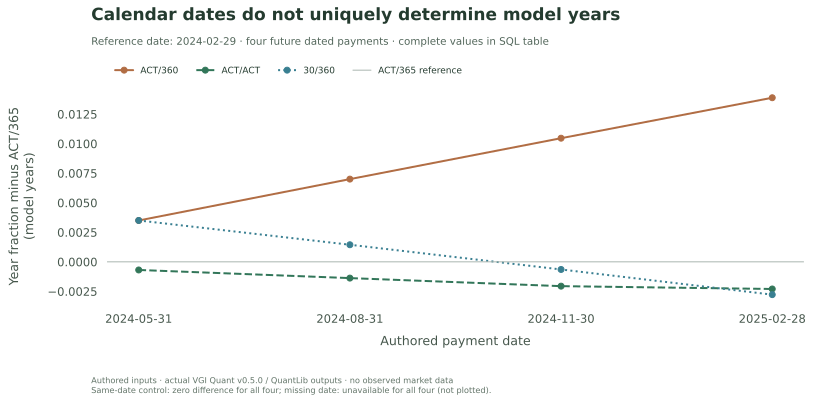

In [11]:
display(values_frame[["id","payment_date","amount","convention","actual_days","year_fraction","discount_factor","present_value"]])
example.fractions(values_frame)

### Reconcile discount factors and present values

With continuous compounding, `discount_factor = exp(−rate × years)` and `present_value = amount × discount_factor`. Recompute both formulas in SQL. Holding the numeric annual rate fixed across conventions is a controlled sensitivity experiment; converting a quoted instrument rate between conventions would require its contractual definitions.

In [12]:
%%sql summary <<
SELECT convention,count(*) AS input_rows,count(present_value) AS valued_rows,
 count(*) FILTER(WHERE present_value IS NULL) AS unavailable_rows,
 sum(amount) FILTER(WHERE present_value IS NOT NULL) AS known_amount,
 sum(present_value) AS known_pv_subtotal,
 sum(amount) FILTER(WHERE present_value IS NULL) AS amount_without_value
FROM valued GROUP BY convention ORDER BY convention;

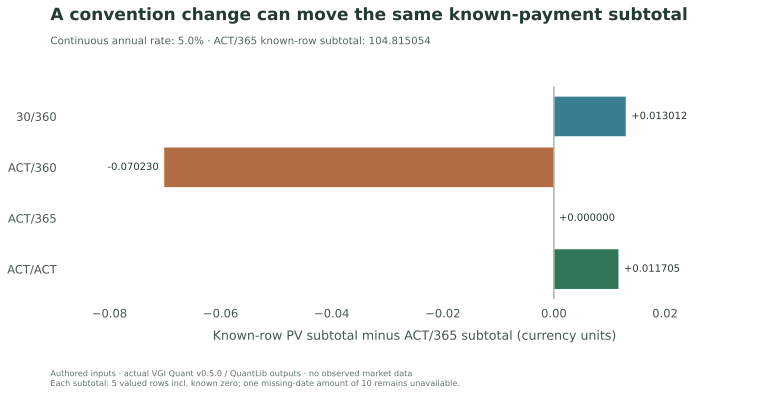

,convention,input_rows,valued_rows,unavailable_rows,known_amount,known_pv_subtotal,amount_without_value
0,30/360,6,5,1,110.0,104.828067,10.0
1,ACT/360,6,5,1,110.0,104.744824,10.0
2,ACT/365,6,5,1,110.0,104.815054,10.0
3,ACT/ACT,6,5,1,110.0,104.826759,10.0


Each convention retains **six records**: five valued rows including one true zero, plus one unavailable present value. The known amounts total **110.00**, while **10.00** has no date. At **5.0% continuous annual rate**, the four known-row subtotals span **0.083243 currency units**. That spread reflects model conventions; none of these is a complete-schedule valuation.

In [13]:
example.present_values(values_frame,CONTINUOUS_RATE)
display(summary)
spread=summary.known_pv_subtotal.max()-summary.known_pv_subtotal.min()
prose(f"Each convention retains **six records**: five valued rows including one true zero, plus one unavailable present value. The known amounts total **{summary.known_amount.iloc[0]:.2f}**, while **{summary.amount_without_value.iloc[0]:.2f}** has no date. At **{CONTINUOUS_RATE:.1%} continuous annual rate**, the four known-row subtotals span **{spread:.6f} currency units**. That spread reflects model conventions; none of these is a complete-schedule valuation.")
export=Path("artifacts/data/03");export.mkdir(parents=True,exist_ok=True)
values_frame.to_csv(export/"values.csv",index=False);summary.to_csv(export/"summary.csv",index=False)

### Check arithmetic and missingness explicitly

The independent arithmetic checks use only conventions with stated formulas, while the worker supplies US BondBasis and ISDA results. All four participate in formula reconciliation, roster accounting and the experiment; no unsupported 365-day shortcut is imposed on ISDA.

In [14]:
%%sql checks <<
SELECT 'full four-by-six roster' AS check_name,(SELECT count(*)=24 AND count(DISTINCT(convention,id))=24 FROM valued) AS passed
UNION ALL SELECT 'registry and evaluated names match',(SELECT count(*)=0 FROM ((SELECT name FROM conventions EXCEPT SELECT convention FROM valued) UNION ALL (SELECT convention FROM valued EXCEPT SELECT name FROM conventions)))
UNION ALL SELECT 'one missing valuation per convention',(SELECT bool_and(unavailable_rows=1 AND valued_rows=5 AND input_rows=6) FROM (SELECT convention,count(*) input_rows,count(present_value) valued_rows,count(*) FILTER(WHERE present_value IS NULL) unavailable_rows FROM valued GROUP BY convention))
UNION ALL SELECT 'missing dates propagate',(SELECT bool_and(year_fraction IS NULL AND discount_factor IS NULL AND present_value IS NULL) FROM valued WHERE payment_date IS NULL)
UNION ALL SELECT 'same-date zero is known',(SELECT bool_and(year_fraction=0 AND discount_factor=1 AND present_value=0) FROM valued WHERE id=1)
UNION ALL SELECT 'ACT360 agrees with actual days',(SELECT max(abs(year_fraction-actual_days/360.0))<1e-12 FROM valued WHERE convention='ACT/360')
UNION ALL SELECT 'ACT365 agrees with actual days',(SELECT max(abs(year_fraction-actual_days/365.0))<1e-12 FROM valued WHERE convention='ACT/365')
UNION ALL SELECT 'continuous discount formula',(SELECT max(abs(discount_factor-exp(-annual_rate*year_fraction)))<1e-12 FROM valued)
UNION ALL SELECT 'present value formula',(SELECT max(abs(present_value-amount*discount_factor))<1e-10 FROM valued)
UNION ALL SELECT 'known discount factors in0to1',(SELECT bool_and(discount_factor>0 AND discount_factor<=1) FROM valued WHERE payment_date IS NOT NULL)
UNION ALL SELECT 'known amount remains110',(SELECT min(total)=110 AND max(total)=110 FROM (SELECT sum(amount) total FROM valued WHERE payment_date IS NOT NULL GROUP BY convention));

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(f"**{len(checks)} roster and numerical SQL checks passed.**")

,check_name,passed
0,full four-by-six roster,True
1,registry and evaluated names match,True
2,one missing valuation per convention,True
3,missing dates propagate,True
4,same-date zero is known,True
5,ACT360 agrees with actual days,True
6,ACT365 agrees with actual days,True
7,continuous discount formula,True
8,present value formula,True
9,known discount factors in0to1,True


**11 roster and numerical SQL checks passed.**

### Focused experiment: change only the continuous rate

Change **`CONTINUOUS_RATE` from 0.05 to 0.10**. Dates, nominal amounts, actual days and all year fractions must remain unchanged. Each strictly future positive payment should have a smaller present value; the same-date zero and missing-date row keep their distinct states. Compare known-row subtotals and ACT/365-relative differences without interpreting these authored rates as market forecasts.

In [16]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-quant](https://github.com/vgi-quant)
